### Implementation of IPLA for Byesian logistic regression

In [10]:
from pathlib import Path
import numpy as np 
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

We use synthetic data, generated using experiments/ipla/scripts/data_generation.py

In [11]:
data = np.load("../data/synthetic_logistic_regression.npz")

for name in data.files:
    print(name, data[name].shape, data[name].dtype)

v = jnp.asarray(data["v"])
y = jnp.asarray(data["y"])
x_true = jnp.asarray(data["x_true"])

v (900, 3) float32
y (900,) float32
x_true (3,) float32
probabilities (900,) float32


I computed the U-gradients w.r.t. $\theta$ and $x$ to be the following:
$$
\nabla_\theta U(\theta,x)=\frac{\theta-x}{\sigma^2},\\

\nabla_x U(\theta,x)=\frac{x-\theta}{\sigma^2}
+\sum_{j=1}^{d_y}\bigl(s(v_j^\top x)-y_j\bigr)v_j.
$$

In [21]:
def Ugrad_th (theta, x, sigma=0.01):
    "Returns the U-gradient w.r.t. theta"
    return (theta-x) / sigma**2

def Ugrad_x(theta, x, v, y, sigma=0.01):
    "Returns the U-gradient w.r.t. x"
    return (x - theta) / sigma**2 + (jax.nn.sigmoid(v @ x) - y) @ v

def ipla(N, gamma, n_iter, theta0, x0, key, grad_th, grad_x):
    theta = theta0
    x = x0
    theta_history = [theta]
    x_history = [x]

    #make grads work for particle clouds
    grad_th_particles = jax.vmap(grad_th, in_axes=(None, 0))
    grad_x_particles = jax.vmap(grad_x, in_axes=(None, 0))

    for _ in range(n_iter):
        key, key_theta, key_particles = jax.random.split(key, 3)
        xi_theta = jax.random.normal(key_theta, shape=(3,))
        xi_x = jax.random.normal(key_particles, shape=(N, 3))

        theta_grad = jnp.sum(grad_th_particles(theta, x), axis=0)
        x_grad = grad_x_particles(theta, x)

        theta = theta - gamma / N * theta_grad + jnp.sqrt(2 * gamma / N) * xi_theta
        x = x - gamma * x_grad + jnp.sqrt(2 * gamma) * xi_x

        theta_history.append(theta)
        x_history.append(x)

    return theta, jnp.stack(theta_history), jnp.stack(x_history)




In [31]:
# Run the experiment
N = 200
gamma = 0.0001
n_iter = 2000

theta0 = jnp.zeros(3)

key = jax.random.key(108)
key, key_x, key_ipla = jax.random.split(key, 3)

x0 = jax.random.normal(key_x, shape=(N, 3))

grad_th = Ugrad_th
grad_x = lambda theta, x: Ugrad_x(theta, x, v, y)

theta_final, theta_history, x_history = ipla(
    N, gamma, n_iter, theta0, x0, key_ipla, grad_th, grad_x
)

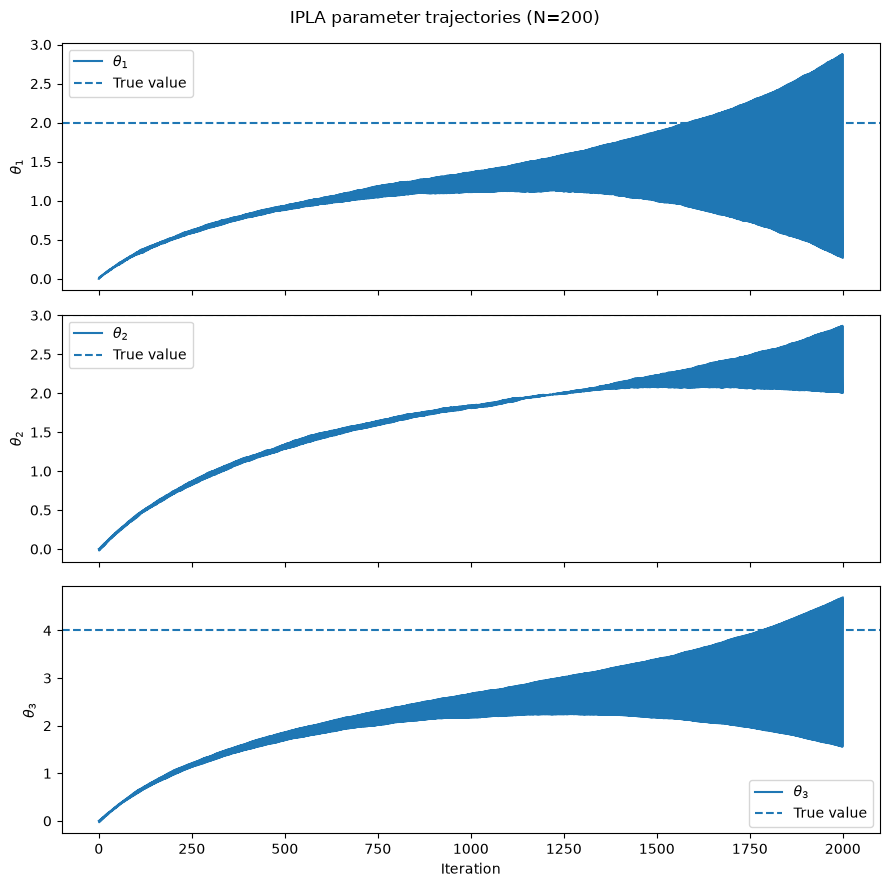

In [ ]:
theta_history = np.asarray(theta_history)
theta_true = np.array([2.0, 3.0, 4.0])

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(theta_history[:, i], label=f"$\\theta_{i+1}$")
    ax.axhline(theta_true[i], linestyle="--", label="True value")
    ax.set_ylabel(f"$\\theta_{i+1}$")
    ax.legend()

axes[-1].set_xlabel("Iteration")
fig.suptitle(f"IPLA parameter trajectories (N={N})")
plt.tight_layout()
plt.show()

In [24]:
print("Final theta:", theta_final)
print("Particle min:", x_history.min())
print("Particle max:", x_history.max())
print("Any NaNs in particles:", jnp.isnan(x_history).any())
print("Any NaNs in theta:", jnp.isnan(theta_history).any())

Final theta: [0.5288253 0.7117232 1.0263655]
Particle min: -2.7269974
Particle max: 2.7088962
Any NaNs in particles: False
Any NaNs in theta: False
